
  H2: ANOVA — Utilization Rate across Clusters — Adult ICUs
  k = 2, n = 1096

  Cluster Means and Standard Deviations:
    Cluster 0:  n = 356, mean = 0.8694, SD = 0.0163, min = 0.8300, max = 0.9000
    Cluster 1:  n = 740, mean = 0.8441, SD = 0.0169, min = 0.8000, max = 0.8900

  ANOVA Results:
    F-statistic:        F(1, 1094) = 553.2409
    p-value:            p = 0.000000  ***
    Effect size (η²):   0.3359  (large)
    Significance:       Yes (p < 0.05)

  Interpretation:
    Utilization rates differ significantly across clusters.
    Cluster membership explains 33.6% of variance in utilization (large effect).
    High-strain cluster (Cluster 0) operates at 0.8694 utilization
    vs low-strain cluster (Cluster 1) at 0.8441 (difference: 0.0253).
    This confirms H2: multi-constraint regimes are associated with higher utilization.


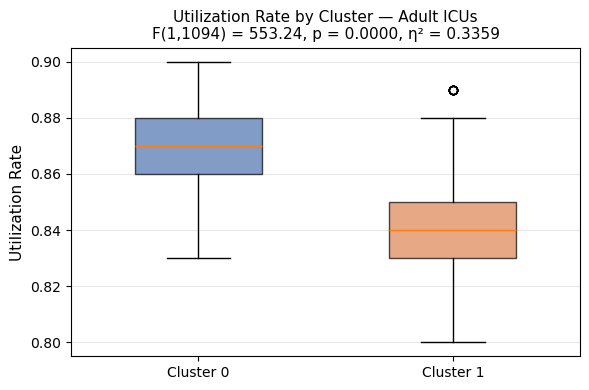

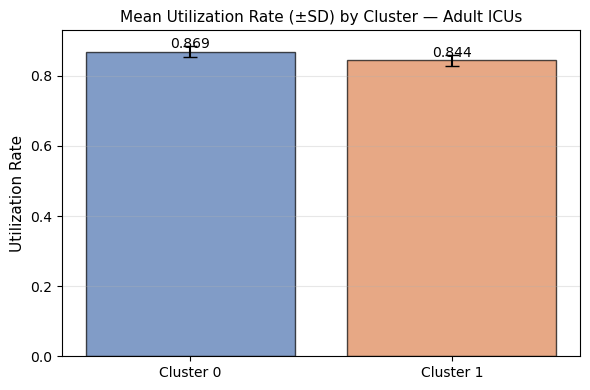


  H2: ANOVA — Utilization Rate across Clusters — PICU
  k = 2, n = 1096

  Cluster Means and Standard Deviations:
    Cluster 0:  n = 445, mean = 0.6708, SD = 0.0381, min = 0.5800, max = 0.7800
    Cluster 1:  n = 651, mean = 0.6129, SD = 0.0360, min = 0.5300, max = 0.7100

  ANOVA Results:
    F-statistic:        F(1, 1094) = 652.5494
    p-value:            p = 0.000000  ***
    Effect size (η²):   0.3736  (large)
    Significance:       Yes (p < 0.05)

  Interpretation:
    Utilization rates differ significantly across clusters.
    Cluster membership explains 37.4% of variance in utilization (large effect).
    High-strain cluster (Cluster 0) operates at 0.6708 utilization
    vs low-strain cluster (Cluster 1) at 0.6129 (difference: 0.0579).
    This confirms H2: multi-constraint regimes are associated with higher utilization.


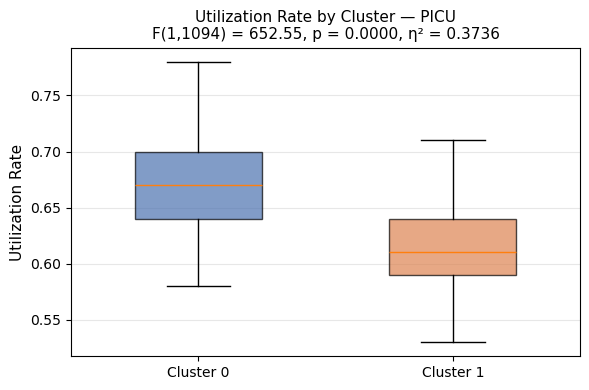

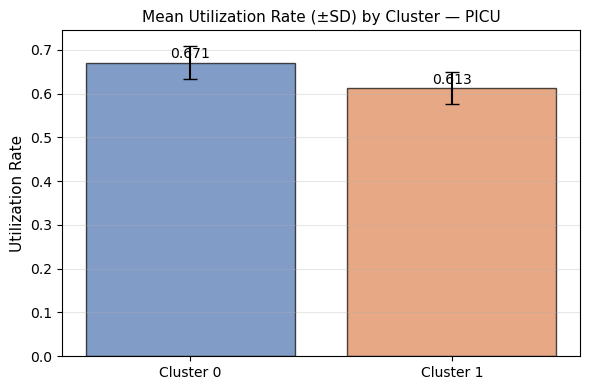


  H2: ANOVA — Utilization Rate across Clusters — NICU
  k = 3, n = 1096

  Cluster Means and Standard Deviations:
    Cluster 0:  n = 797, mean = 0.6468, SD = 0.0262, min = 0.5900, max = 0.7200
    Cluster 1:  n = 71, mean = 0.6876, SD = 0.0126, min = 0.6500, max = 0.7100
    Cluster 2:  n = 228, mean = 0.6871, SD = 0.0150, min = 0.6500, max = 0.7200

  ANOVA Results:
    F-statistic:        F(2, 1093) = 319.6418
    p-value:            p = 0.000000  ***
    Effect size (η²):   0.3690  (large)
    Significance:       Yes (p < 0.05)

  Interpretation:
    Utilization rates differ significantly across clusters.
    Cluster membership explains 36.9% of variance in utilization (large effect).

  Post-hoc Tukey HSD (pairwise comparisons):
    Cluster 0 vs Cluster 1:  diff = -0.0408, p = 0.000000  ***
    Cluster 0 vs Cluster 2:  diff = -0.0403, p = 0.000000  ***
    Cluster 1 vs Cluster 2:  diff = 0.0005, p = 0.988889  n.s.

  Post-hoc Interpretation:
    Clusters 1 and 2 do not differ sig

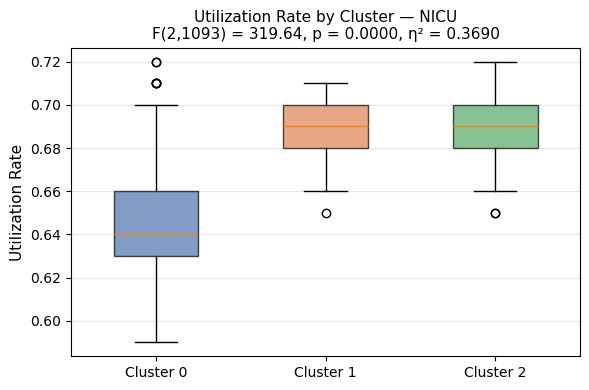

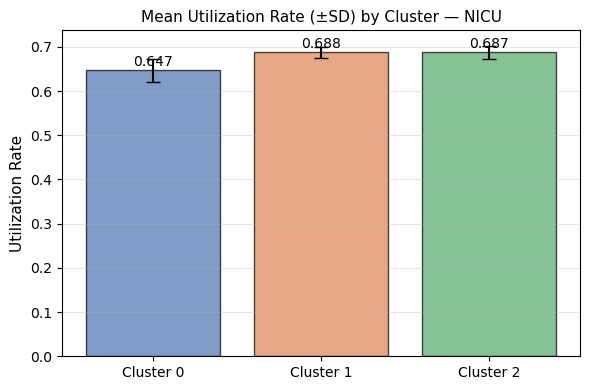


=== H2 Complete ===


In [5]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import stats
from scipy.stats import tukey_hsd
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Load data
# ──────────────────────────────────────────────
df = pd.read_csv('Intensivregister_file.csv', sep=';', decimal=',', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

numeric_cols = ['reporting_units', 'current_covid_cases', 'icu_beds_occupied', 'icu_beds_available',
                'material_constraints', 'staff_constraints', 'space_constraints', 'total_icu_capacity',
                'utilization_rate', 'slack_rate', 'staff_constraint_rate', 'material_constraint_rate',
                'space_constraint_rate', 'utilization_rate_z', 'slack_rate_z',
                'staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# ──────────────────────────────────────────────
# 2. Config per care type (k from H1 results)
# ──────────────────────────────────────────────
config = {
    'ERWACHSENE': {'label': 'Adult ICUs', 'k': 2},
    'PICU':       {'label': 'PICU',       'k': 2},
    'NICU':       {'label': 'NICU',       'k': 3}
}

features_z = ['staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']
cluster_colors = ['#4C72B0', '#DD8452', '#55A868']

# ──────────────────────────────────────────────
# 3. Run H2 for each care type
# ──────────────────────────────────────────────
for group, cfg in config.items():
    subset = df[df['care_group'] == group].copy()
    subset.reset_index(drop=True, inplace=True)

    X = subset[features_z].values
    k = cfg['k']
    label = cfg['label']

    # Cluster assignment (same as H1)
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    subset['cluster'] = km.fit_predict(X)

    print(f"\n{'='*60}")
    print(f"  H2: ANOVA — Utilization Rate across Clusters — {label}")
    print(f"  k = {k}, n = {len(subset)}")
    print(f"{'='*60}")

    # ──────────────────────────────────────────
    # Cluster means and SDs
    # ──────────────────────────────────────────
    print(f"\n  Cluster Means and Standard Deviations:")
    groups = []
    for c in sorted(subset['cluster'].unique()):
        mask = subset['cluster'] == c
        vals = subset.loc[mask, 'utilization_rate']
        groups.append(vals)
        print(f"    Cluster {c}:  n = {len(vals)}, "
              f"mean = {vals.mean():.4f}, SD = {vals.std():.4f}, "
              f"min = {vals.min():.4f}, max = {vals.max():.4f}")

    # ──────────────────────────────────────────
    # One-way ANOVA
    # ──────────────────────────────────────────
    f_stat, p_value = stats.f_oneway(*groups)

    df_between = k - 1
    df_within = len(subset) - k
    df_total = len(subset) - 1

    ss_between = sum(len(g) * (g.mean() - subset['utilization_rate'].mean())**2 for g in groups)
    ss_total = sum((subset['utilization_rate'] - subset['utilization_rate'].mean())**2)
    eta_squared = ss_between / ss_total

    if eta_squared > 0.14:
        effect_label = "large"
    elif eta_squared > 0.06:
        effect_label = "medium"
    elif eta_squared > 0.01:
        effect_label = "small"
    else:
        effect_label = "negligible"

    print(f"\n  ANOVA Results:")
    print(f"    F-statistic:        F({df_between}, {df_within}) = {f_stat:.4f}")
    print(f"    p-value:            p = {p_value:.6f}  {'***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'n.s.'}")
    print(f"    Effect size (η²):   {eta_squared:.4f}  ({effect_label})")
    print(f"    Significance:       {'Yes (p < 0.05)' if p_value < 0.05 else 'No (p >= 0.05)'}")

    # ──────────────────────────────────────────
    # Interpretation
    # ──────────────────────────────────────────
    print(f"\n  Interpretation:")
    if p_value < 0.05:
        print(f"    Utilization rates differ significantly across clusters.")
        print(f"    Cluster membership explains {eta_squared*100:.1f}% of variance in utilization ({effect_label} effect).")
        if k == 2:
            high_c = 0 if groups[0].mean() > groups[1].mean() else 1
            low_c = 1 - high_c
            diff = abs(groups[0].mean() - groups[1].mean())
            print(f"    High-strain cluster (Cluster {high_c}) operates at {groups[high_c].mean():.4f} utilization")
            print(f"    vs low-strain cluster (Cluster {low_c}) at {groups[low_c].mean():.4f} (difference: {diff:.4f}).")
            print(f"    This confirms H2: multi-constraint regimes are associated with higher utilization.")
    else:
        print(f"    No significant difference in utilization across clusters.")

    # ──────────────────────────────────────────
    # Post-hoc Tukey HSD (only for k > 2)
    # ──────────────────────────────────────────
    if k > 2:
        print(f"\n  Post-hoc Tukey HSD (pairwise comparisons):")
        result = tukey_hsd(*[g.values for g in groups])

        cluster_ids = sorted(subset['cluster'].unique())
        for i in range(len(cluster_ids)):
            for j in range(i + 1, len(cluster_ids)):
                ci, cj = cluster_ids[i], cluster_ids[j]
                p_pair = result.pvalue[i][j]
                diff = groups[i].mean() - groups[j].mean()
                sig = '***' if p_pair < 0.001 else '**' if p_pair < 0.01 else '*' if p_pair < 0.05 else 'n.s.'
                print(f"    Cluster {ci} vs Cluster {cj}:  diff = {diff:.4f}, p = {p_pair:.6f}  {sig}")

        print(f"\n  Post-hoc Interpretation:")
        # Check which pairs are significant
        p_01 = result.pvalue[0][1]
        p_02 = result.pvalue[0][2]
        p_12 = result.pvalue[1][2]
        if p_01 < 0.05 and p_02 < 0.05 and p_12 >= 0.05:
            print(f"    Clusters 1 and 2 do not differ significantly from each other,")
            print(f"    but both differ significantly from Cluster 0.")
            print(f"    This suggests two distinct constraint profiles produce similar utilization pressure.")
        elif p_01 < 0.05 and p_02 < 0.05 and p_12 < 0.05:
            print(f"    All three clusters differ significantly from each other.")
            print(f"    Each constraint regime corresponds to a distinct utilization level.")
        else:
            print(f"    Mixed significance pattern — review pairwise results above.")

    # ──────────────────────────────────────────
    # PLOT — Boxplot utilization by cluster
    # ──────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6, 4))
    data_list = [g.values for g in groups]
    cluster_labels = [f'Cluster {c}' for c in sorted(subset['cluster'].unique())]
    bp = ax.boxplot(data_list, tick_labels=cluster_labels, patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], cluster_colors[:k]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_ylabel('Utilization Rate', fontsize=11)
    ax.set_title(f'Utilization Rate by Cluster — {label}\n'
                 f'F({df_between},{df_within}) = {f_stat:.2f}, p = {p_value:.4f}, η² = {eta_squared:.4f}',
                 fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(f'H2_{group}_anova_boxplot.png', dpi=150)
    plt.show()

    # ──────────────────────────────────────────
    # PLOT — Bar chart with error bars
    # ──────────────────────────────────────────
    means = [g.mean() for g in groups]
    sds = [g.std() for g in groups]

    fig, ax = plt.subplots(figsize=(6, 4))
    x_pos = range(k)
    bars = ax.bar(x_pos, means, yerr=sds, capsize=5, color=cluster_colors[:k], alpha=0.7, edgecolor='black')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(cluster_labels, fontsize=10)
    ax.set_ylabel('Utilization Rate', fontsize=11)
    ax.set_title(f'Mean Utilization Rate (±SD) by Cluster — {label}', fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{mean:.3f}', ha='center', fontsize=10)

    plt.tight_layout()
    plt.savefig(f'H2_{group}_anova_barplot.png', dpi=150)
    plt.show()

print("\n=== H2 Complete ===")